In [ ]:
from transformers import AutoImageProcessor, AutoModelForImageClassification
from PIL import Image
import torch 
import os
import numpy as np
from torch.utils.data import DataLoader
from torchvision import transforms
import pandas as pd

import matplotlib.pyplot as plt
import fastparquet
from sklearn.metrics import classification_report
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency, pointbiserialr
from statistics import NormalDist
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import classification_report


In [ ]:
label_to_id = pd.read_csv("Data/label_to_id_mapping.csv").set_index("label")["id"].to_dict()
dx=pd.read_csv("Data/Test_set.csv")

X=dx["X"].tolist()
y=dx["y"].tolist()

In [ ]:
model = AutoModelForImageClassification.from_pretrained(
    "./best_model",
    local_files_only=True
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): Linear(in_features=192, out_features=192, bias=True)
          (k_proj): Linear(in_features=192, out_features=192, bias=True)
          (v_proj): Linear(in_features=192, out_features=192, bias=True)
          (o_proj): Linear(in_features=192, out_features=192, bias=True)
        )
        (layernorm_before): LayerNorm((192,), eps=1e-12, elementwise_affine=True)
        (layernorm_after): LayerNorm((192,), eps=1e-12, elementwise_affine=True)
        (mlp): ViTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=192, out_features=768, bias=True)
          (fc2): Linear(in_features=768, out_f

In [7]:
class CachedImageDataset(torch.utils.data.Dataset):
    def __init__(self, dt, dl, transform=None):
        self.data = []
        self.labels = dl
        self.dt = dt
        self.transform = transform


        for i in range(len(self.dt)):
            path = self.dt[i]
            img = Image.open(path).convert("RGB")
   
            label = torch.tensor(self.labels[i], dtype=torch.long)
            self.data.append((img, label))

            

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        img, label = self.data[index]

        if self.transform:
            img = self.transform(img)

        return img, label

In [ ]:
#test model

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5],
    ),
])




test_dataset = CachedImageDataset(X, y, transform=test_transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)
total_correct=0
total_samples=0

class_names = [
    name.replace("train_val_", "")
    for name, class_id in sorted(label_to_id.items(), key=lambda x: x[1])
]

all_true = []
all_predictions = []
all_confidences = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        output = model(pixel_values=images)
        probabilities = torch.softmax(output.logits, dim=1)
        confidences, predictions = probabilities.max(dim=1)

        all_true.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())
        all_confidences.extend(confidences.cpu().tolist())



accuracy = np.mean(np.array(all_true) == np.array(all_predictions))
print(f"Test Accuracy: {accuracy:.4f}")


Test Accuracy: 0.8660


In [9]:
report = classification_report(
    all_true,
    all_predictions,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=3,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()
display(report_df)

,precision,recall,f1-score,support
call,0.815126,0.829060,0.822034,117.000
dislike,0.818182,0.947368,0.878049,95.000
fist,0.913462,0.904762,0.909091,105.000
four,0.940000,0.940000,0.940000,100.000
like,0.850746,0.686747,0.760000,83.000
accuracy,0.866000,0.866000,0.866000,0.866
macro avg,0.867503,0.861587,0.861835,500.000
weighted avg,0.867245,0.866000,0.864254,500.000


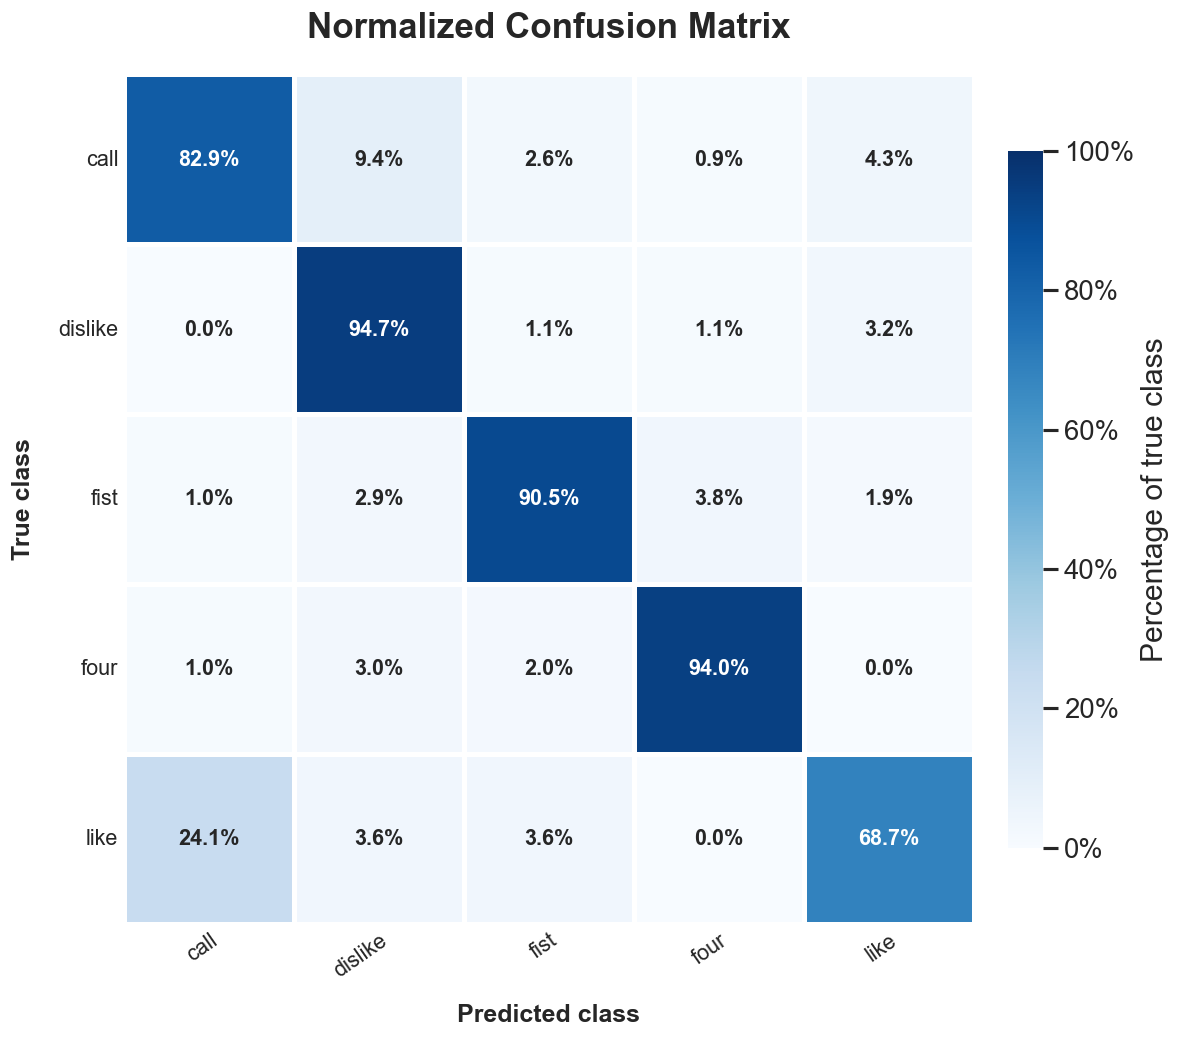

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix
from matplotlib.ticker import PercentFormatter


# Normalized confusion matrix
cm = confusion_matrix(
    all_true,
    all_predictions,
    labels=range(len(class_names)),
    normalize="true"
)

sns.set_theme(style="white", context="talk")

fig, ax = plt.subplots(
    figsize=(11, 9),
    dpi=120
)

heatmap = sns.heatmap(
    cm,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=2,
    linecolor="white",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={
        "fontsize": 13,
        "fontweight": "bold"
    },
    cbar_kws={
        "label": "Percentage of true class",
        "shrink": 0.82,
        "pad": 0.03
    },
    ax=ax
)

# Display color bar as percentages
colorbar = heatmap.collections[0].colorbar
colorbar.ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

ax.set_title(
    "Normalized Confusion Matrix",
    fontsize=21,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Predicted class",
    fontsize=15,
    fontweight="bold",
    labelpad=14
)

ax.set_ylabel(
    "True class",
    fontsize=15,
    fontweight="bold",
    labelpad=14
)

ax.tick_params(
    axis="both",
    labelsize=13,
    length=0
)

plt.xticks(
    rotation=35,
    ha="right",
    rotation_mode="anchor"
)

plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

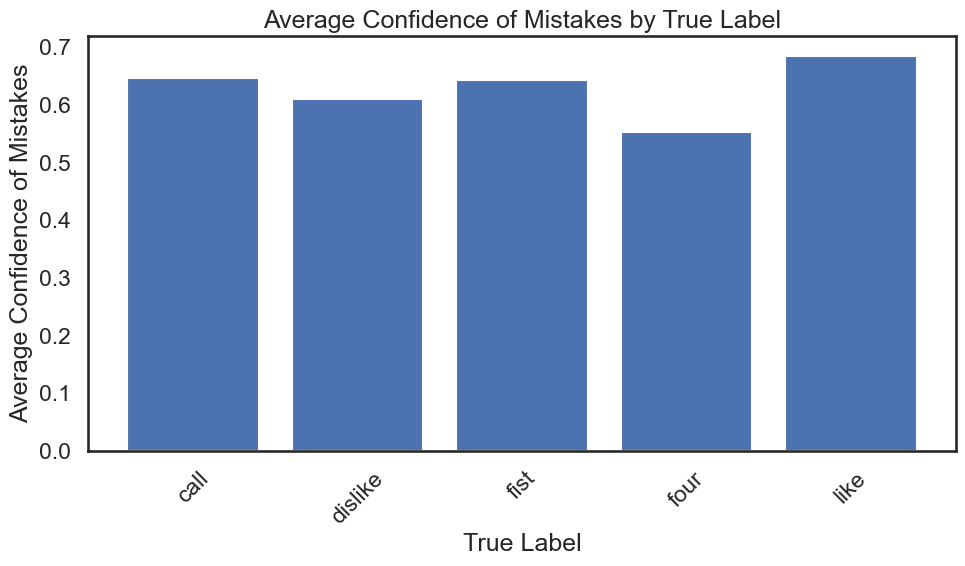

In [11]:
results = pd.DataFrame({
    "file_path": X,
    "true_id": all_true,
    "predicted_id": all_predictions,
    "confidence": all_confidences
})

results["true_label"] = results["true_id"].map(
    dict(enumerate(class_names))
)
results["predicted_label"] = results["predicted_id"].map(
    dict(enumerate(class_names))
)
results["correct"] = results["true_id"] == results["predicted_id"]

mistakes = results[~results["correct"]].sort_values(
    "confidence",
    ascending=False
)

mistakes_grouped=mistakes.groupby("true_label")["confidence"].mean().reset_index()

plt.figure(figsize=(10, 6))
plt.bar(
    mistakes_grouped["true_label"],
    mistakes_grouped["confidence"]
)
plt.xlabel("True Label")
plt.ylabel("Average Confidence of Mistakes")
plt.title("Average Confidence of Mistakes by True Label")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




In [12]:
data = pd.read_csv("Data/data.csv")

data=data[["id","leading_hand", "age","gender","race"]]
results["id"]=results["file_path"].str.split("/").str[-1]
results["id"]=results["id"].str.replace(".jpg", "")

results=pd.merge(results, data, on="id", how="left")

results

,file_path,true_id,predicted_id,confidence,true_label,predicted_label,correct,id,leading_hand,age,gender,race
0,hagrid-sample-30k-384p/hagrid_30k/train_val_di...,1,1,0.967012,dislike,dislike,True,4818fb17-cb3b-4dce-b882-03e43fcec989,left,23.12,female,White
1,hagrid-sample-30k-384p/hagrid_30k/train_val_fi...,2,2,0.943658,fist,fist,True,56ed266f-e822-4a9b-8d5c-61d32d666740,left,42.97,female,White
2,hagrid-sample-30k-384p/hagrid_30k/train_val_fi...,2,2,0.959268,fist,fist,True,6128d3c2-9815-4eac-a2eb-696677ebf7e9,left,36.51,female,White
3,hagrid-sample-30k-384p/hagrid_30k/train_val_di...,1,1,0.930351,dislike,dislike,True,07a80421-7b0d-4d0f-96f1-37c22a1959f1,left,38.15,male,White
4,hagrid-sample-30k-384p/hagrid_30k/train_val_ca...,0,0,0.977681,call,call,True,6674a098-ccb2-46e6-aa20-59eb639a4aa3,left,38.00,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
495,hagrid-sample-30k-384p/hagrid_30k/train_val_fo...,3,3,0.993243,four,four,True,829d0838-4b80-4d9b-9e8a-c17148b97d16,left,24.70,female,White
496,hagrid-sample-30k-384p/hagrid_30k/train_val_ca...,0,0,0.841345,call,call,True,4e9cc64c-c2e5-4c88-97cd-e8fe92960fee,right,41.38,male,White
497,hagrid-sample-30k-384p/hagrid_30k/train_val_ca...,0,0,0.965322,call,call,True,35304810-a878-43de-899d-d532a16db2f3,right,26.63,female,White
498,hagrid-sample-30k-384p/hagrid_30k/train_val_di...,1,1,0.974247,dislike,dislike,True,57d15c2c-1ef5-48da-95a9-5195df6f78db,left,28.52,female,White


In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency, pointbiserialr
from statistics import NormalDist
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="talk")

plt.rcParams.update({
    "figure.facecolor": "#F7F8FC",
    "axes.facecolor": "#FFFFFF",
    "axes.titleweight": "bold",
    "axes.titlesize": 18,
    "axes.labelsize": 15,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "grid.color": "#DDE3EC",
})



analysis = results.copy()

analysis["age"] = pd.to_numeric(
    analysis["age"],
    errors="coerce"
)

analysis["confidence"] = pd.to_numeric(
    analysis["confidence"],
    errors="coerce"
)

analysis["correct_num"] = (
    analysis["correct"]
    .astype(bool)
    .astype(int)
)

for column in ["gender", "leading_hand"]:
    analysis[column] = (
        analysis[column]
        .astype("string")
        .str.strip()
        .str.lower()
    )

analysis.loc[
    ~analysis["gender"].isin(["female", "male"]),
    "gender"
] = pd.NA

analysis.loc[
    ~analysis["leading_hand"].isin(["left", "right"]),
    "leading_hand"
] = pd.NA

overall_accuracy = analysis["correct_num"].mean()

print(f"Number of results: {len(analysis):,}")
print(f"Overall accuracy: {overall_accuracy:.2%}")


def wilson_interval(correct, total, confidence=0.95):
    if total == 0:
        return np.nan, np.nan

    z = NormalDist().inv_cdf(
        1 - (1 - confidence) / 2
    )

    proportion = correct / total
    denominator = 1 + z**2 / total

    center = (
        proportion + z**2 / (2 * total)
    ) / denominator

    margin = (
        z
        * np.sqrt(
            proportion * (1 - proportion) / total
            + z**2 / (4 * total**2)
        )
        / denominator
    )

    return center - margin, center + margin


def group_accuracy(data, column, order):
    summary = (
        data.dropna(subset=[column, "correct_num"])
        .groupby(column, observed=True)["correct_num"]
        .agg(
            accuracy="mean",
            correct="sum",
            sample_size="count"
        )
        .reindex(order)
        .dropna()
        .reset_index()
    )

    intervals = summary.apply(
        lambda row: wilson_interval(
            row["correct"],
            row["sample_size"]
        ),
        axis=1
    )

    summary["ci_low"] = [
        interval[0] for interval in intervals
    ]

    summary["ci_high"] = [
        interval[1] for interval in intervals
    ]

    return summary


def cramers_v(data, category):

    valid = data.dropna(
        subset=[category, "correct_num"]
    )

    table = pd.crosstab(
        valid[category],
        valid["correct_num"]
    )

    if min(table.shape) < 2:
        return np.nan, np.nan

    chi2, p_value, _, _ = chi2_contingency(
        table,
        correction=False
    )

    n = table.to_numpy().sum()

    value = np.sqrt(
        chi2
        / (
            n
            * min(
                table.shape[0] - 1,
                table.shape[1] - 1
            )
        )
    )

    return value, p_value


def draw_accuracy_bar_chart(
    summary,
    category,
    labels,
    colors,
    title,
    effect_value,
    p_value
):


    fig, ax = plt.subplots(
        figsize=(11, 8),
        dpi=120
    )

    positions = np.arange(len(summary))

    lower_error = (
        summary["accuracy"] - summary["ci_low"]
    )

    upper_error = (
        summary["ci_high"] - summary["accuracy"]
    )

    bar_colors = [
        colors[value]
        for value in summary[category]
    ]

    bars = ax.bar(
        positions,
        summary["accuracy"],
        width=0.58,
        color=bar_colors,
        edgecolor="none",
        yerr=[lower_error, upper_error],
        error_kw={
            "ecolor": "#374151",
            "elinewidth": 2.2,
            "capsize": 8,
            "capthick": 2.2
        }
    )

    ax.axhline(
        overall_accuracy,
        color="#374151",
        linestyle="--",
        linewidth=2,
        label=f"Overall accuracy: {overall_accuracy:.1%}"
    )

    bar_labels = [
        f"{accuracy:.1%}\n"
        f"n = {int(sample_size)}"
        for accuracy, sample_size in zip(
            summary["accuracy"],
            summary["sample_size"]
        )
    ]

    ax.bar_label(
        bars,
        labels=bar_labels,
        padding=12,
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xticks(positions)

    ax.set_xticklabels(
        [
            labels[value]
            for value in summary[category]
        ],
        fontsize=16,
        fontweight="bold"
    )

    limit_values = np.concatenate([
        summary["ci_low"].to_numpy(),
        summary["ci_high"].to_numpy(),
        np.array([overall_accuracy])
    ])

    ax.set_ylim(
        max(0, limit_values.min() - 0.10),
        min(1, limit_values.max() + 0.14)
    )

    ax.yaxis.set_major_formatter(
        PercentFormatter(1)
    )

    ax.set_ylabel("Prediction accuracy")
    ax.set_xlabel("")

    ax.set_title(
        f"{title}\n"
        f"Cramér's V = {effect_value:.3f}, "
        f"p = {p_value:.3g}",
        pad=20
    )

    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, -0.16),
        frameon=False
    )

    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)

    plt.tight_layout()
    plt.show()

Number of results: 500
Overall accuracy: 86.60%


,gender,accuracy,correct,sample_size,ci_low,ci_high
0,female,0.845283,224,265,0.796840,0.883858
1,male,0.900498,181,201,0.851313,0.934661


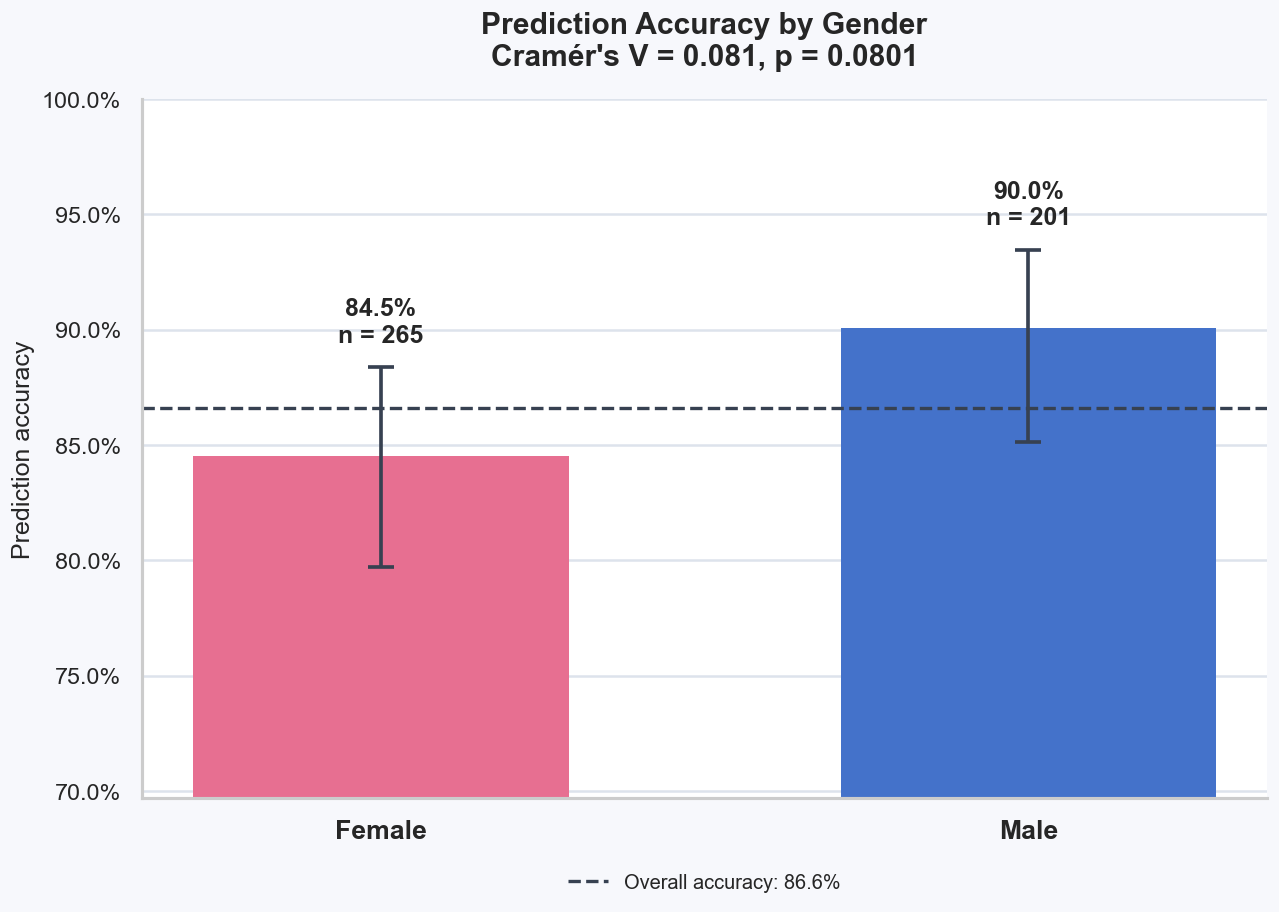

In [14]:
gender_summary = group_accuracy(
    analysis,
    column="gender",
    order=["female", "male"]
)

v_gender, p_gender = cramers_v(
    analysis,
    category="gender"
)

display(gender_summary)

draw_accuracy_bar_chart(
    summary=gender_summary,
    category="gender",
    labels={
        "female": "Female",
        "male": "Male"
    },
    colors={
        "female": "#E76F91",
        "male": "#4472CA"
    },
    title="Prediction Accuracy by Gender",
    effect_value=v_gender,
    p_value=p_gender
)

,leading_hand,accuracy,correct,sample_size,ci_low,ci_high
0,left,0.851695,201,236,0.800732,0.891392
1,right,0.878788,232,264,0.833893,0.912817


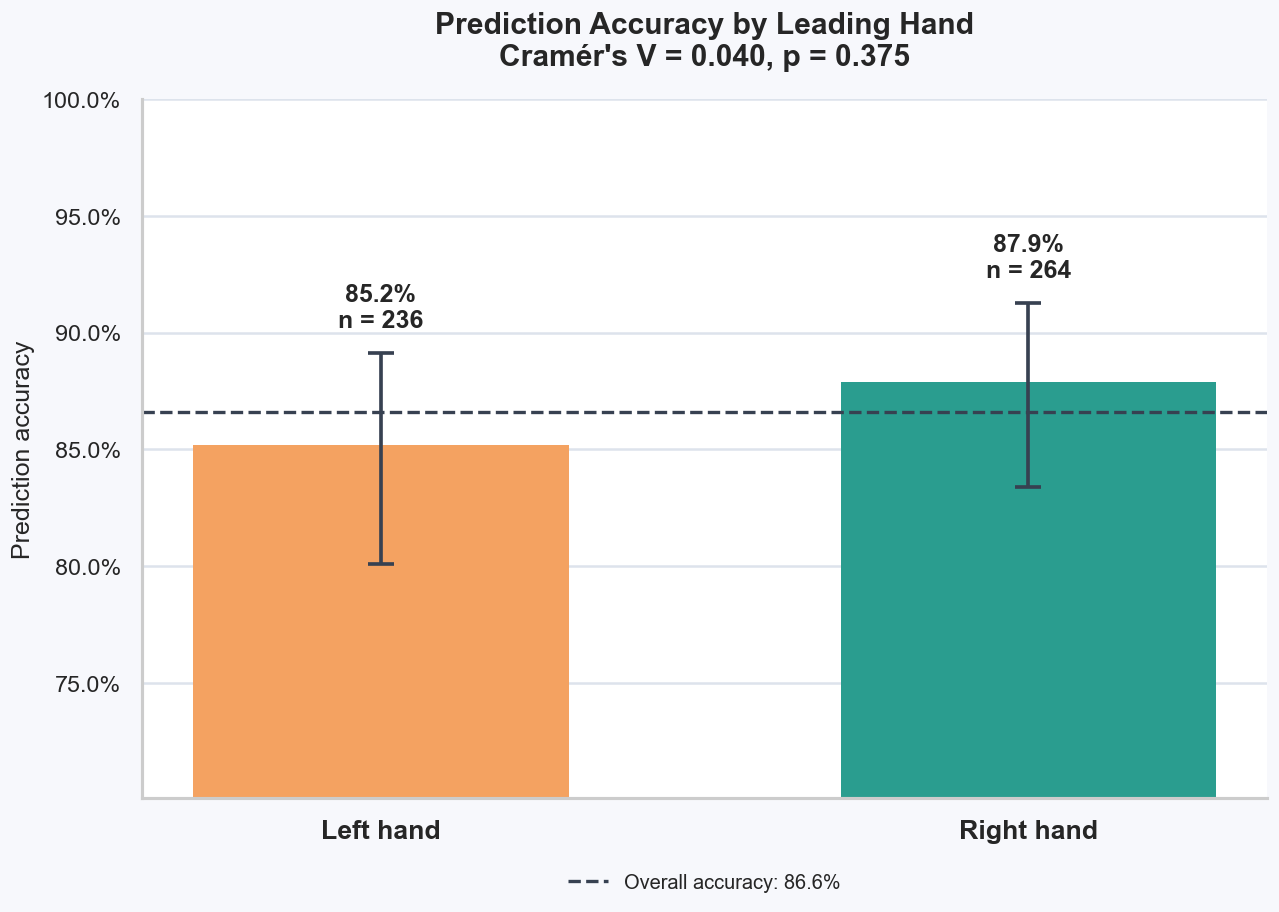

In [15]:
hand_summary = group_accuracy(
    analysis,
    column="leading_hand",
    order=["left", "right"]
)

v_hand, p_hand = cramers_v(
    analysis,
    category="leading_hand"
)

display(hand_summary)

draw_accuracy_bar_chart(
    summary=hand_summary,
    category="leading_hand",
    labels={
        "left": "Left hand",
        "right": "Right hand"
    },
    colors={
        "left": "#F4A261",
        "right": "#2A9D8F"
    },
    title="Prediction Accuracy by Leading Hand",
    effect_value=v_hand,
    p_value=p_hand
)

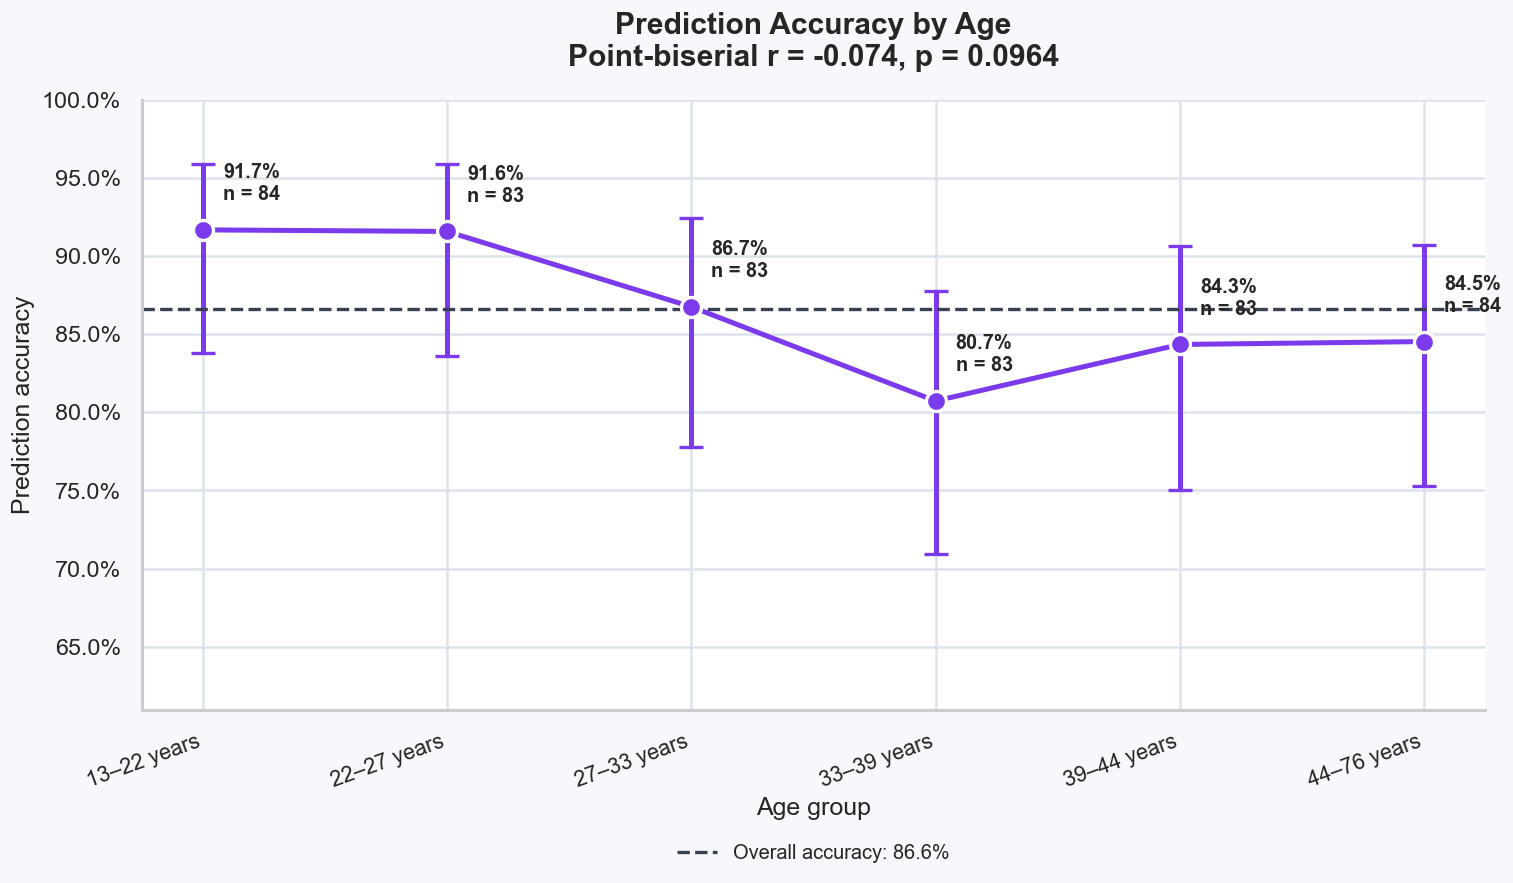

In [16]:
age_data = analysis.dropna(
    subset=["age", "correct_num"]
).copy()

r_age, p_age = pointbiserialr(
    age_data["correct_num"],
    age_data["age"]
)

# Groups with approximately equal sample sizes
age_data["age_group"] = pd.qcut(
    age_data["age"],
    q=6,
    duplicates="drop"
)

age_summary = (
    age_data
    .groupby("age_group", observed=True)
    .agg(
        accuracy=("correct_num", "mean"),
        correct=("correct_num", "sum"),
        sample_size=("correct_num", "count"),
        mean_age=("age", "mean")
    )
    .reset_index()
)

age_intervals = age_summary.apply(
    lambda row: wilson_interval(
        row["correct"],
        row["sample_size"]
    ),
    axis=1
)

age_summary["ci_low"] = [
    interval[0] for interval in age_intervals
]

age_summary["ci_high"] = [
    interval[1] for interval in age_intervals
]

age_summary["age_label"] = age_summary["age_group"].apply(
    lambda interval:
        f"{interval.left:.0f}–{interval.right:.0f} years"
)

fig, ax = plt.subplots(
    figsize=(13, 8),
    dpi=120
)

positions = np.arange(len(age_summary))

lower_error = (
    age_summary["accuracy"] - age_summary["ci_low"]
)

upper_error = (
    age_summary["ci_high"] - age_summary["accuracy"]
)

ax.errorbar(
    positions,
    age_summary["accuracy"],
    yerr=[lower_error, upper_error],
    color="#7C3AED",
    marker="o",
    markersize=12,
    markeredgecolor="white",
    markeredgewidth=2,
    linewidth=3,
    capsize=7
)

ax.axhline(
    overall_accuracy,
    color="#374151",
    linestyle="--",
    linewidth=2,
    label=f"Overall accuracy: {overall_accuracy:.1%}"
)

for position, row in age_summary.iterrows():
    ax.annotate(
        f"{row['accuracy']:.1%}\n"
        f"n = {int(row['sample_size'])}",
        xy=(position, row["accuracy"]),
        xytext=(12, 18),
        textcoords="offset points",
        ha="left",
        fontsize=12,
        fontweight="bold"
    )

ax.set_xticks(positions)

ax.set_xticklabels(
    age_summary["age_label"],
    rotation=20,
    ha="right",
    fontsize=13
)

limit_values = np.concatenate([
    age_summary["ci_low"].to_numpy(),
    age_summary["ci_high"].to_numpy(),
    np.array([overall_accuracy])
])

ax.set_ylim(
    max(0, limit_values.min() - 0.10),
    min(1, limit_values.max() + 0.14)
)

ax.yaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.set_xlabel("Age group")
ax.set_ylabel("Prediction accuracy")

ax.set_title(
    "Prediction Accuracy by Age\n"
    f"Point-biserial r = {r_age:+.3f}, "
    f"p = {p_age:.3g}",
    pad=20
)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, -0.28),
    frameon=False
)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

,race,accuracy,correct,sample_size,ci_low,ci_high
0,White,0.877990,367,418,0.843126,0.905971
1,Black,0.600000,3,5,0.230724,0.882379
2,Asian,0.882353,15,17,0.656636,0.967120


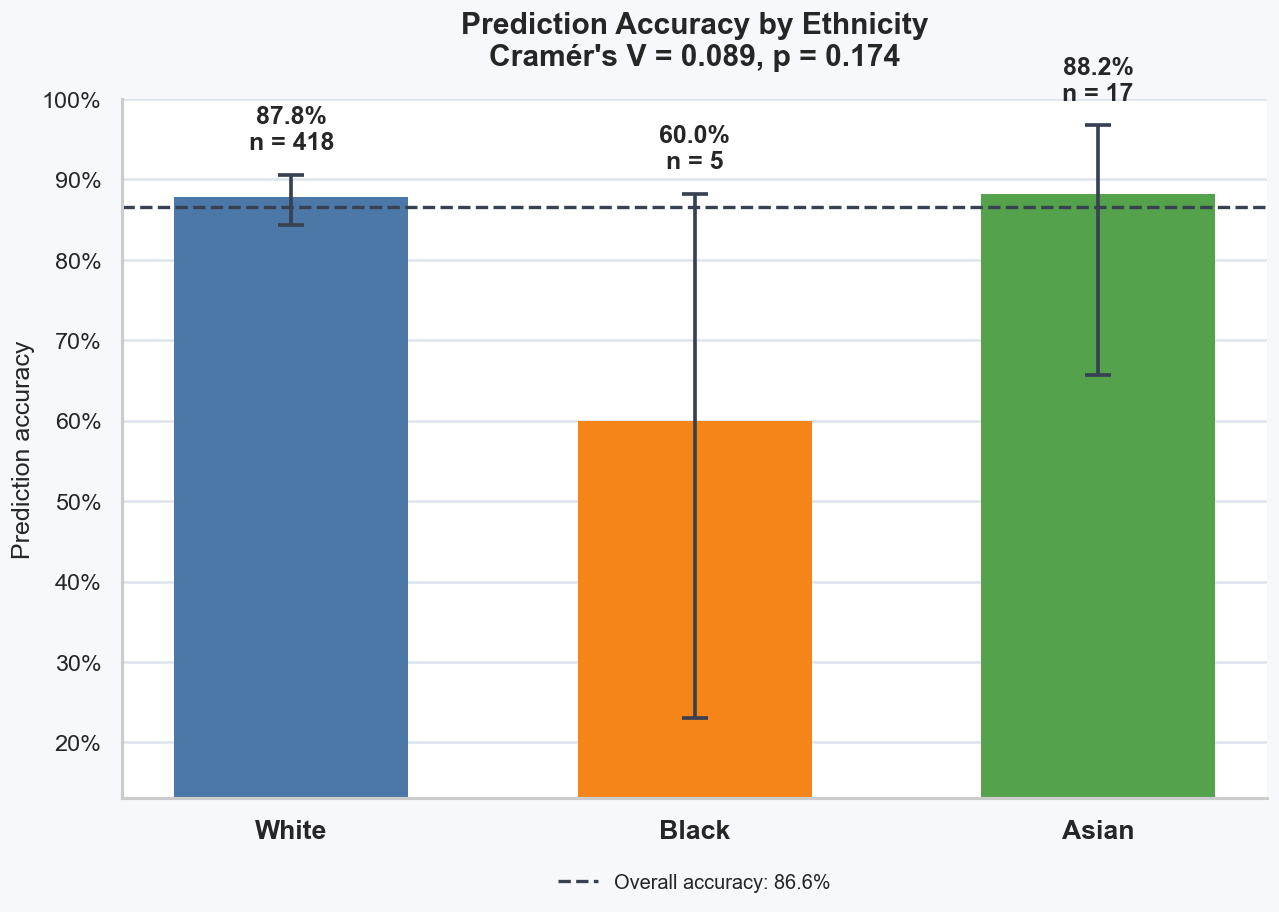

In [17]:
# Prepare ethnicity/race values
analysis["race"] = (
    analysis["race"]
    .astype("string")
    .str.strip()
    .str.title()
)

race_order = [
    "White",
    "Black",
    "Asian"
]

# Keep only the selected groups
analysis.loc[
    ~analysis["race"].isin(race_order),
    "race"
] = pd.NA


# Calculate accuracy by ethnicity
ethnicity_summary = group_accuracy(
    analysis,
    column="race",
    order=race_order
)

# Measure relationship with prediction correctness
v_race, p_race = cramers_v(
    analysis,
    category="race"
)

display(ethnicity_summary)


# Create the bar chart
draw_accuracy_bar_chart(
    summary=ethnicity_summary,
    category="race",
    labels={
        "White": "White",
        "Black": "Black",
        "Asian": "Asian"
    },
    colors={
        "White": "#4C78A8",
        "Black": "#F58518",
        "Asian": "#54A24B"
    },
    title="Prediction Accuracy by Ethnicity",
    effect_value=v_race,
    p_value=p_race
)


Mean decision threshold: 85.3%


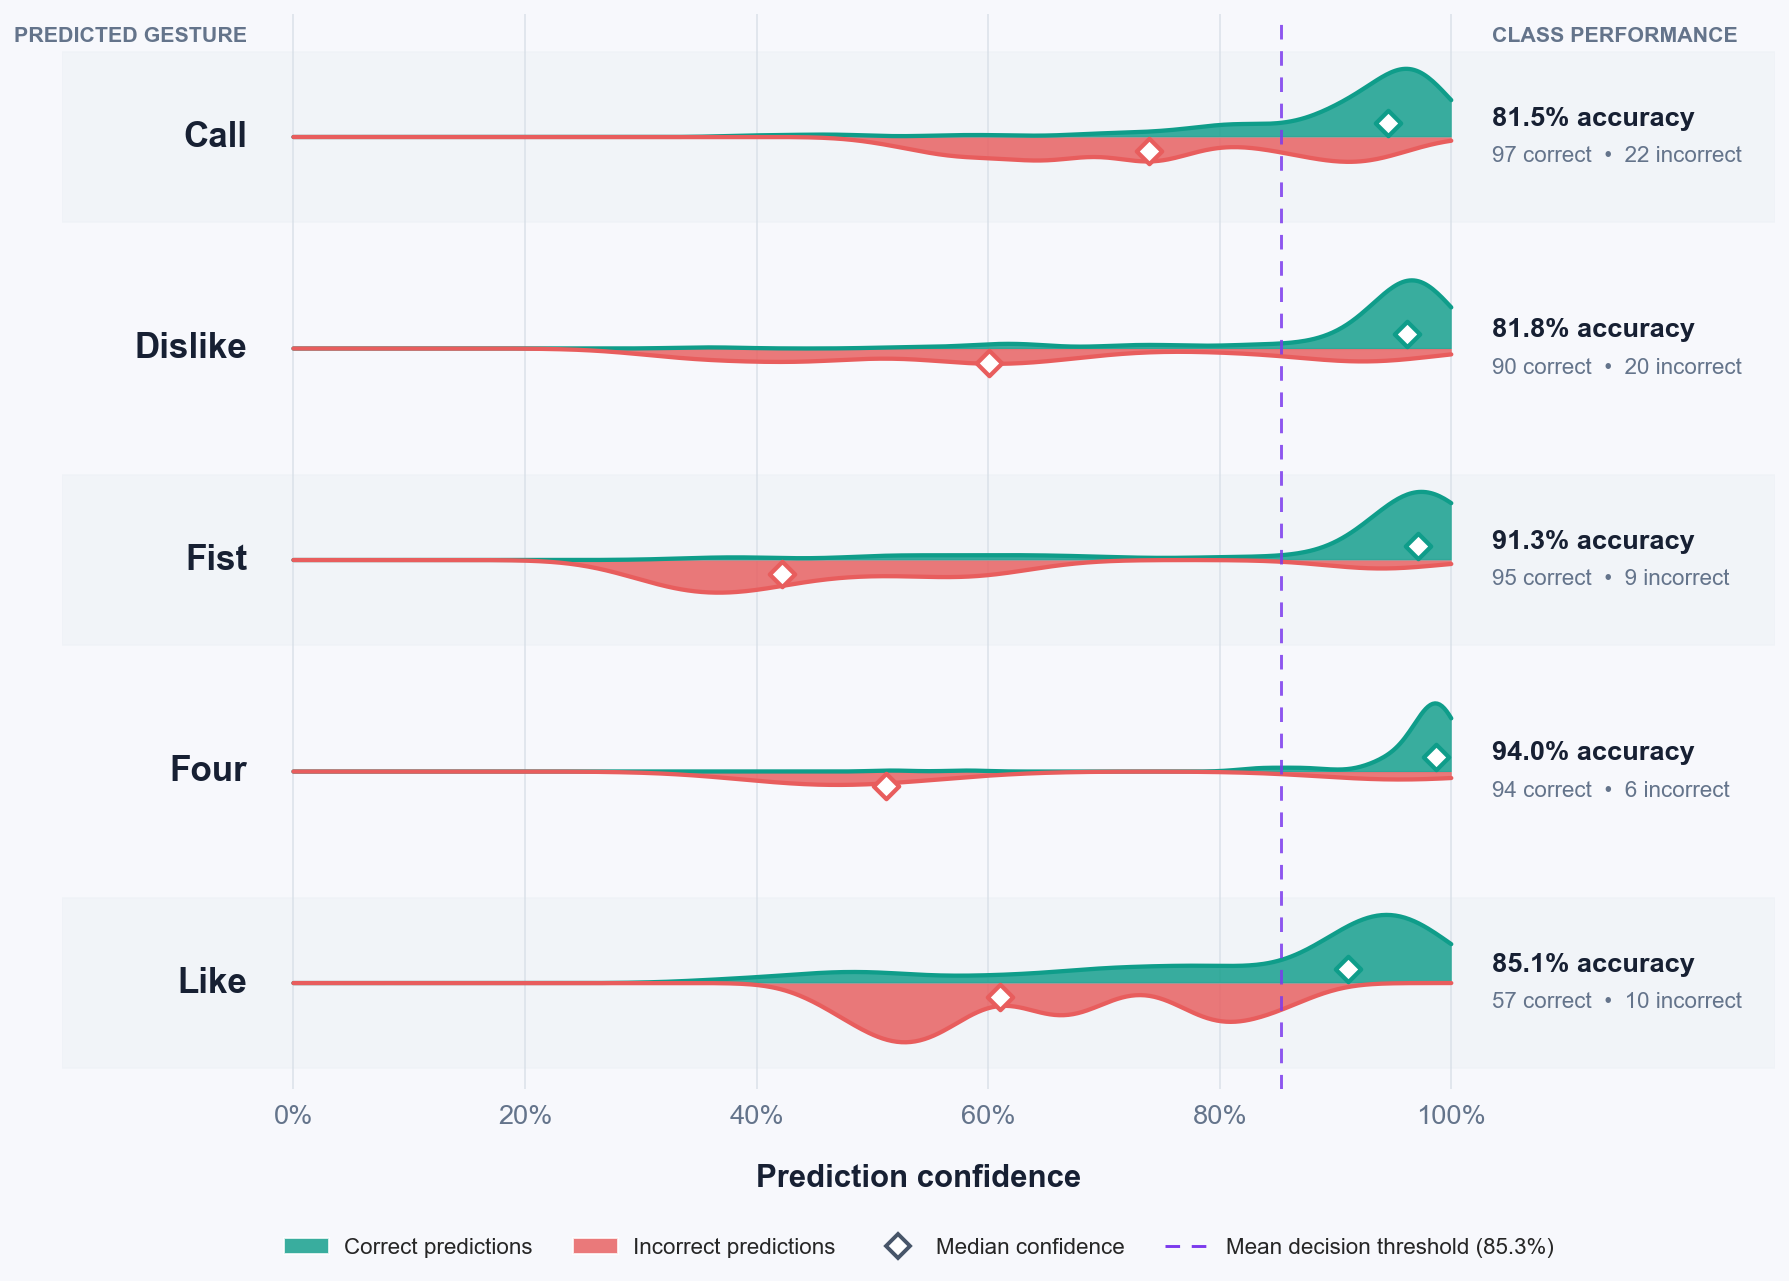

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import gaussian_kde
from sklearn.metrics import roc_curve
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter



confidence_data = results[
    [
        "confidence",
        "predicted_label",
        "correct"
    ]
].copy()

confidence_data["confidence"] = (
    pd.to_numeric(
        confidence_data["confidence"],
        errors="coerce"
    )
    .clip(0, 1)
)

confidence_data = confidence_data.dropna(
    subset=[
        "confidence",
        "predicted_label",
        "correct"
    ]
)

confidence_data["outcome"] = np.where(
    confidence_data["correct"].astype(bool),
    "Correct",
    "Incorrect"
)

class_order = [
    class_name
    for class_name in class_names
    if class_name
    in confidence_data["predicted_label"].unique()
]


x_grid = np.linspace(0, 1, 500)


def confidence_density(values):
    values = np.asarray(
        values,
        dtype=float
    )

    if len(values) == 0:
        return np.zeros_like(x_grid)

    if len(values) == 1 or np.std(values) < 1e-6:
        center = values.mean()

        return np.exp(
            -0.5
            * ((x_grid - center) / 0.025) ** 2
        )

    kde = gaussian_kde(
        values,
        bw_method=0.25
    )

    return kde(x_grid)



class_thresholds = []

for class_name in class_order:
    class_data = confidence_data[
        confidence_data["predicted_label"].eq(
            class_name
        )
    ]

    true_outcome = (
        class_data["outcome"]
        .eq("Correct")
        .astype(int)
    )

    confidence_scores = class_data[
        "confidence"
    ]


    if true_outcome.nunique() < 2:
        continue

    (
        false_positive_rate,
        true_positive_rate,
        thresholds
    ) = roc_curve(
        true_outcome,
        confidence_scores
    )

    finite = np.isfinite(thresholds)

    youden_j = (
        true_positive_rate[finite]
        - false_positive_rate[finite]
    )

    optimal_threshold = thresholds[finite][
        np.argmax(youden_j)
    ]

    class_thresholds.append(
        optimal_threshold
    )


if len(class_thresholds) > 0:
    mean_decision_threshold = np.mean(
        class_thresholds
    )
else:
    mean_decision_threshold = (
        confidence_data["confidence"].mean()
    )

print(
    f"Mean decision threshold: "
    f"{mean_decision_threshold:.1%}"
)



sns.set_theme(style="white")

correct_color = "#0F9D8A"
incorrect_color = "#E85D5D"
decision_color = "#7C3AED"

background_color = "#F7F8FC"
alternate_row_color = "#EEF2F7"
line_color = "#CBD5E1"
text_color = "#172033"
secondary_text = "#64748B"

fig, ax = plt.subplots(
    figsize=(18, 12),
    dpi=140
)

fig.patch.set_facecolor(
    background_color
)

ax.set_facecolor(
    background_color
)

row_spacing = 1.8

row_positions = (
    np.arange(len(class_order))[::-1]
    * row_spacing
)


for row_number, (base_y, class_name) in enumerate(
    zip(row_positions, class_order)
):
    class_data = confidence_data[
        confidence_data["predicted_label"].eq(
            class_name
        )
    ]

    correct_values = class_data.loc[
        class_data["outcome"].eq("Correct"),
        "confidence"
    ].to_numpy()

    incorrect_values = class_data.loc[
        class_data["outcome"].eq("Incorrect"),
        "confidence"
    ].to_numpy()

    correct_curve = confidence_density(
        correct_values
    )

    incorrect_curve = confidence_density(
        incorrect_values
    )

    maximum_density = max(
        correct_curve.max(),
        incorrect_curve.max(),
        1e-9
    )

    scale = 0.58 / maximum_density

    correct_curve *= scale
    incorrect_curve *= scale


    if row_number % 2 == 0:
        ax.axhspan(
            base_y - 0.72,
            base_y + 0.72,
            color=alternate_row_color,
            alpha=0.65,
            zorder=0
        )



    ax.hlines(
        base_y,
        0,
        1,
        color=line_color,
        linewidth=1.2,
        zorder=1
    )


    
    ax.fill_between(
        x_grid,
        base_y,
        base_y + correct_curve,
        color=correct_color,
        alpha=0.82,
        linewidth=0,
        zorder=2
    )

    ax.plot(
        x_grid,
        base_y + correct_curve,
        color=correct_color,
        linewidth=2.2,
        zorder=3
    )


    ax.fill_between(
        x_grid,
        base_y,
        base_y - incorrect_curve,
        color=incorrect_color,
        alpha=0.82,
        linewidth=0,
        zorder=2
    )

    ax.plot(
        x_grid,
        base_y - incorrect_curve,
        color=incorrect_color,
        linewidth=2.2,
        zorder=3
    )


    if len(correct_values) > 0:
        correct_median = np.median(
            correct_values
        )

        ax.scatter(
            correct_median,
            base_y + 0.12,
            marker="D",
            s=85,
            facecolor="white",
            edgecolor=correct_color,
            linewidth=2.2,
            zorder=5
        )


    if len(incorrect_values) > 0:
        incorrect_median = np.median(
            incorrect_values
        )

        ax.scatter(
            incorrect_median,
            base_y - 0.12,
            marker="D",
            s=85,
            facecolor="white",
            edgecolor=incorrect_color,
            linewidth=2.2,
            zorder=5
        )



    ax.text(
        -0.04,
        base_y,
        class_name.title(),
        ha="right",
        va="center",
        fontsize=18,
        fontweight="bold",
        color=text_color
    )



    number_correct = len(
        correct_values
    )

    number_incorrect = len(
        incorrect_values
    )

    total = len(class_data)

    class_accuracy = (
        number_correct / total
        if total > 0
        else np.nan
    )

    ax.text(
        1.035,
        base_y + 0.16,
        f"{class_accuracy:.1%} accuracy",
        ha="left",
        va="center",
        fontsize=14,
        fontweight="bold",
        color=text_color
    )

    ax.text(
        1.035,
        base_y - 0.16,
        (
            f"{number_correct} correct  •  "
            f"{number_incorrect} incorrect"
        ),
        ha="left",
        va="center",
        fontsize=11.5,
        color=secondary_text
    )



ax.axvline(
    mean_decision_threshold,
    color=decision_color,
    linestyle=(0, (5, 4)),
    linewidth=1.5,
    alpha=0.85,
    zorder=4
)


overall_accuracy = confidence_data[
    "correct"
].mean()




# Column headings
ax.text(
    -0.04,
    row_positions[0] + 0.78,
    "PREDICTED GESTURE",
    ha="right",
    va="bottom",
    fontsize=11,
    fontweight="bold",
    color=secondary_text
)

ax.text(
    1.035,
    row_positions[0] + 0.78,
    "CLASS PERFORMANCE",
    ha="left",
    va="bottom",
    fontsize=11,
    fontweight="bold",
    color=secondary_text
)



ax.set_xlim(
    -0.20,
    1.28
)

ax.set_ylim(
    row_positions[-1] - 0.90,
    row_positions[0] + 1.05
)

ax.set_xticks(
    np.linspace(0, 1, 6)
)

ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

ax.set_xlabel(
    "Prediction confidence",
    fontsize=16,
    fontweight="bold",
    color=text_color,
    labelpad=18
)

ax.set_yticks([])

ax.tick_params(
    axis="x",
    labelsize=14,
    colors=secondary_text,
    length=0,
    pad=8
)

ax.grid(
    axis="x",
    color="#D5DCE5",
    linewidth=0.8,
    alpha=0.8
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

legend_elements = [
    Patch(
        facecolor=correct_color,
        alpha=0.82,
        label="Correct predictions"
    ),
    Patch(
        facecolor=incorrect_color,
        alpha=0.82,
        label="Incorrect predictions"
    ),
    Line2D(
        [0],
        [0],
        marker="D",
        color="none",
        markerfacecolor="white",
        markeredgecolor="#475569",
        markeredgewidth=2,
        markersize=9,
        label="Median confidence"
    ),
    Line2D(
        [0],
        [0],
        color=decision_color,
        linestyle=(0, (5, 4)),
        linewidth=1.5,
        label=(
            "Mean decision threshold "
            f"({mean_decision_threshold:.1%})"
        )
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    frameon=False,
    fontsize=11.5,
    handletextpad=0.7,
    columnspacing=1.8
)


fig.subplots_adjust(
    top=0.82,
    bottom=0.18,
    left=0.12,
    right=0.80
)

plt.show()